# 07 · Rollout test: a switchback experiment, sized on real data

**Why not a normal A/B test?** Drivers are shared. If half the trips in Midtown get the new pay
and half the old, a driver who accepts a well-paid trip is no longer available for the next
request, whichever group it belongs to: the two groups compete for the same drivers and the
difference between them is biased (interference). The fix is to randomize **whole markets for a
period of time**: a region runs the new policy for a block of hours, then switches back, in a
random schedule (a *switchback* test).

**Design choices, decided here before any test runs**
* **Unit:** region (borough × zone cluster) × time block.
* **Block length:** long enough that most trips start and finish under one policy and drivers
  respond to it; short enough to give many units. Compared below: 1, 2 and 4 hours.
* **Carryover:** at a switch, drivers are still positioned for the previous policy. The first hour
  of each block is excluded from the analysis as a wash-out (compared with keeping it).
* **Randomization:** balanced: within each region and day, half the blocks are treated.
* **Primary metric:** margin per trip (rider fare − driver pay). **Guardrails:** mean rider wait and
  trips per block (a proxy for acceptance and completion).
* **Analysis:** difference in means with region × hour-of-week fixed effects; standard errors
  clustered by region-day; checked by an A/A test.

**Sizing on real data.** The variance that decides the test's power comes from how real outcomes
vary from block to block. This notebook uses the real zone × hour table for the last four weeks
of data, plants a known effect, and measures power by simulation.

In [1]:
import numpy as np
import pandas as pd

from ridepay import data, plots
from ridepay.records import read_metrics, show_verdict, write_metrics, metrics_dir

SOURCE = data.source()
FAST = SOURCE != "real"
con = data.connect()
clusters = data.load_table("zone_clusters")
con.register("clusters", clusters[["zone", "cluster_name", "borough"]])
reg = con.sql("""
    SELECT c.borough || ' · ' || c.cluster_name AS region, z.hour,
           SUM(z.trips) AS trips, SUM(z.fare - z.driver_pay) AS margin, SUM(z.wait_sum_sec) AS wait_sum_sec,
           SUM(z.wait_n) AS wait_n
    FROM zone_hour z JOIN clusters c USING (zone)
    WHERE c.cluster_name NOT IN ('Sparse') AND z.hour >= (SELECT MAX(hour) FROM zone_hour) - INTERVAL 28 DAY
    GROUP BY ALL
""").df()
vol = reg.groupby("region")["trips"].sum()
keep = vol[vol >= 20_000 * (0.02 if FAST else 1)].index          # regions with enough trips to run a test in
reg = reg[reg["region"].isin(keep)].copy()
reg["day"] = reg["hour"].dt.normalize()
reg["how"] = reg["hour"].dt.dayofweek * 24 + reg["hour"].dt.hour
print(f"{reg['region'].nunique()} regions, {reg['hour'].nunique()} hours ({reg['hour'].min():%d %b} – {reg['hour'].max():%d %b %Y})")
reg.groupby("region")["trips"].sum().sort_values(ascending=False).head(10)

12 regions, 673 hours (02 Jun – 30 Jun 2025)


region
Manhattan · Core                        5197912.0
Brooklyn · Core                         2992879.0
Queens · Commuter residential           2513786.0
Bronx · Commuter residential            2366726.0
Brooklyn · Commuter residential         2105980.0
Manhattan · Commuter residential        1492758.0
Queens · Core                            888825.0
Queens · Airports                        719208.0
Staten Island · Commuter residential     268461.0
Queens · Long waits                       49734.0
Name: trips, dtype: float64

## The expected effect, from phase 6

In [2]:
try:
    p6 = read_metrics("06_policy_simulation", metrics_dir(SOURCE))
    held = p6["held_summary"]
    today, robust = held["Today"], held["Optimized (robust)"]
    pay_change = robust["pay_per_trip"] - today["pay_per_trip"]
    expected = float(-pay_change)        # margin per trip moves by minus the change in pay per trip
except FileNotFoundError:
    expected = 0.10
print(f"expected change in margin per trip from the policy: ${expected:+.3f}")

expected change in margin per trip from the policy: $+0.163


## Power by simulation

For each design, draw many random balanced schedules on the real data:
* with **no effect** (an A/A test): the spread of the estimates across schedules is the design's
  true noise, the basis for *randomization inference*. We also record how often the usual
  cluster-robust standard error would call the A/A result "significant";
* with a planted effect δ (dollars of margin per trip; half of it in the first hour after a switch,
  as carryover): the mean estimate shows the design's bias.

Power for each δ then follows from the randomization distribution: an estimate is significant when it
is more than 1.96 randomization standard deviations from zero.

In [3]:
from scipy.stats import norm  # noqa: E402

rng = np.random.default_rng(7)


def assign(df, block_h):
    """A random balanced schedule: within each region and day, a random half of the blocks are treated."""
    d = df.copy()
    d["block"] = d["hour"].dt.hour // block_h
    blocks = d[["region", "day", "block"]].drop_duplicates()
    blocks["u"] = rng.random(len(blocks))
    blocks["rank"] = blocks.groupby(["region", "day"])["u"].rank()
    n_per = blocks.groupby(["region", "day"])["block"].transform("size")
    blocks["treat"] = (blocks["rank"] <= n_per / 2).astype(int)
    d = d.merge(blocks[["region", "day", "block", "treat"]], on=["region", "day", "block"])
    d = d.sort_values(["region", "hour"])
    prev = d.groupby("region")["treat"].shift(1)
    d["first_hour"] = (d["treat"] != prev).astype(int)       # first hour after a switch
    return d


def estimate(d, delta, washout, outcome="margin"):
    """Plant an effect of delta $ per trip (half in the first hour after a switch) and estimate it."""
    d = d.copy()
    if outcome == "margin":
        lift = np.where(d["first_hour"] == 1, 0.5, 1.0) * delta * d["treat"]
        d["y"] = (d["margin"] + lift * d["trips"]) / d["trips"]
    else:
        d["y"] = d["wait_sum_sec"] / d["wait_n"] / 60
    if washout:
        d = d[d["first_hour"] == 0]
    return fe_effect(d)


def fe_effect(d):
    """Weighted regression of y on treat with region x hour-of-week fixed effects (by demeaning),
    standard error clustered by region-day."""
    w = d["trips"].to_numpy(float)
    g = (d["region"] + "|" + d["how"].astype(str)).to_numpy()
    codes = pd.factorize(g)[0]
    sw = np.bincount(codes, w)

    def demean(x):
        return x - (np.bincount(codes, w * x) / sw)[codes]

    y, t = demean(d["y"].to_numpy(float)), demean(d["treat"].to_numpy(float))
    beta = (w * t * y).sum() / (w * t * t).sum()
    e = y - beta * t
    cl = pd.factorize(d["region"] + d["day"].dt.strftime("%m%d"))[0]
    score = np.bincount(cl, w * t * e)
    se = np.sqrt((score**2).sum()) / (w * t * t).sum()
    return beta, se


designs = [(1, False), (2, False), (2, True), (4, True)]
R_AA = 30 if FAST else 150
R_EFF = 10 if FAST else 40
DELTA = 0.20
rows = []
for block_h, washout in designs:
    aa_est, aa_sig = [], 0
    for _ in range(R_AA):
        b, se = estimate(assign(reg, block_h), 0.0, washout)
        aa_est.append(b)
        aa_sig += abs(b / se) > 1.96
    eff = [estimate(assign(reg, block_h), DELTA, washout)[0] for _ in range(R_EFF)]
    rows.append({"block_h": block_h, "washout": washout, "sd_randomization": float(np.std(aa_est, ddof=1)),
                 "aa_false_positive_cluster_se": aa_sig / R_AA,
                 "bias_share": float((np.mean(eff) - DELTA) / DELTA)})
design = pd.DataFrame(rows).set_index(["block_h", "washout"])
design["mde_4wk"] = 2.8 * design["sd_randomization"] / (1 + design["bias_share"])     # bias shrinks the effect seen
design["weeks_for_expected"] = np.ceil(4 * (design["mde_4wk"] / max(abs(expected), 1e-6)) ** 2).astype(int)
design.round(3)

sd_randomization  aa_false_positive_cluster_se  bias_share  \
block_h washout                                                               
1       False               0.046                         0.067      -0.324   
2       False               0.060                         0.087      -0.137   
        True                0.079                         0.133       0.013   
4       True                0.078                         0.100      -0.065   

                 mde_4wk  weeks_for_expected  
block_h washout                               
1       False      0.190                   6  
2       False      0.196                   6  
        True       0.220                   8  
4       True       0.235                   9

**Reading.** The cluster-robust standard error is too small for switchbacks (its A/A false-positive
rate is above 5%: outcomes are correlated across neighbouring blocks in ways region-day clusters don't
capture), so the test will be analysed with randomization inference. Designs without a wash-out
under-estimate the effect (carryover from the previous block dilutes it); dropping the first hour
removes that bias but throws data away.

**Rule for choosing, fixed in advance:** among designs whose bias is under 10% of the effect, take
the one that needs the fewest weeks.

chosen design: (np.int64(2), np.True_)


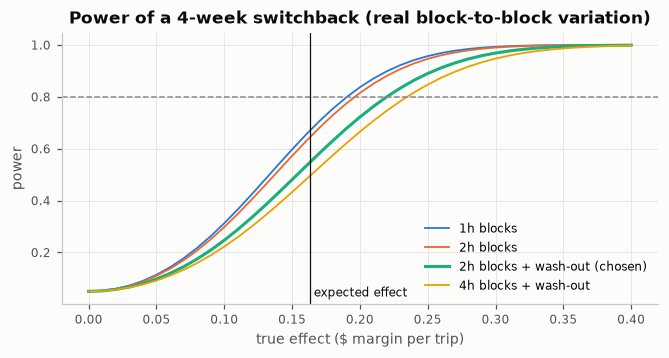

In [4]:
ok = design[design["bias_share"].abs() < 0.10]
choice = (ok if len(ok) else design)["weeks_for_expected"].idxmin()
grid = np.linspace(0, 0.4, 41)
fig, ax = plots.subplots(figsize=(7, 3.2))
for i, (key, r) in enumerate(design.iterrows()):
    pw = norm.sf(1.96 - grid * (1 + r["bias_share"]) / r["sd_randomization"]) + norm.cdf(-1.96 - grid * (1 + r["bias_share"]) / r["sd_randomization"])
    ax.plot(grid, pw, color=plots.SERIES[i], lw=2 if key == choice else 1.2,
            label=f"{key[0]}h blocks{' + wash-out' if key[1] else ''}{' (chosen)' if key == choice else ''}")
ax.axhline(0.8, color=plots.GREY, ls="--", lw=1)
ax.axvline(abs(expected), color=plots.INK, lw=0.8)
ax.text(abs(expected), 0.03, " expected effect", fontsize=8, color=plots.INK)
ax.set(title="Power of a 4-week switchback (real block-to-block variation)", xlabel="true effect ($ margin per trip)",
       ylabel="power")
ax.legend()
data.savefig(fig, "07_switchback_power")
print("chosen design:", choice)

## Guardrail: can the test see a change in waits?

In [5]:
aa = [estimate(assign(reg, choice[0]), 0.0, choice[1], outcome="wait") for _ in range(R_AA)]
wait_sd = float(np.std([a[0] for a in aa]))
print(f"rider wait: sd of the A/A estimate {wait_sd:.3f} min → minimum detectable change ≈ {2.8 * wait_sd:.2f} min")

rider wait: sd of the A/A estimate 0.036 min → minimum detectable change ≈ 0.10 min


## Pre-registered decision rule

Written now, before the test:
1. Run the chosen design (below) for the planned number of weeks; no early stopping on the primary
   metric.
2. **Ship** if the 95% CI for margin per trip excludes zero in the right direction **and** the mean
   rider wait is not worse by more than its non-inferiority margin (the larger of 0.25 min and the
   test's detectable change) **and** driver earnings per hour per region are within 5% of control.
3. **Don't ship** if any guardrail fails, whatever the margin result. If the margin CI includes
   zero with guardrails fine, extend once by the same length; then decide.
4. Report effects by region; a region with a significantly negative effect is excluded from the
   rollout and investigated.

In [6]:
record = {"regions": int(reg["region"].nunique()), "weeks": 4, "expected_effect": expected,
          "design": design.reset_index().round(5).to_dict(orient="records"),
          "chosen": {"block_h": int(choice[0]), "washout": bool(choice[1])},
          "wait_mde_min": 2.8 * wait_sd, "replications": {"aa": R_AA, "effect": R_EFF}}
_ = write_metrics("07_switchback", record, SOURCE)

## Verdict

In [7]:
c = design.loc[choice]
label = f"{choice[0]}-hour blocks" + (", first hour washed out" if choice[1] else "")
show_verdict(
    "Verdict: phase 8, switchback test design",
    [
        f"**Randomize regions × time blocks: {label}.** Across {record['regions']} regions, the chosen design's bias from "
        f"carryover is {c['bias_share']:+.0%} of the effect; designs without a wash-out under-state it by up to "
        f"{-design['bias_share'].min():.0%}.",
        f"**Sized on real variation:** minimum detectable effect ${c['mde_4wk']:.3f} margin per trip in 4 weeks; the "
        f"policy's expected effect is ${expected:+.3f} per trip, so plan for {int(c['weeks_for_expected'])} week(s).",
        f"**Analyse with randomization inference, not cluster-robust errors**: in A/A simulations the usual clustered "
        f"standard error flags {design['aa_false_positive_cluster_se'].mean():.0%} of null results as significant (should "
        "be 5%); the spread across re-randomized schedules is the honest yardstick.",
        f"**Guardrail sensitivity:** the same test detects a change in mean rider wait of about {2.8 * wait_sd:.2f} min, "
        "so the wait non-inferiority margin is the larger of 0.25 min and that.",
    ],
    "write the decision memo and ship the package.",
)

### Verdict: phase 8, switchback test design

1. **Randomize regions × time blocks: 2-hour blocks, first hour washed out.** Across 12 regions, the chosen design's bias from carryover is +1% of the effect; designs without a wash-out under-state it by up to 32%.
2. **Sized on real variation:** minimum detectable effect \$0.220 margin per trip in 4 weeks; the policy's expected effect is \$+0.163 per trip, so plan for 8 week(s).
3. **Analyse with randomization inference, not cluster-robust errors**: in A/A simulations the usual clustered standard error flags 10% of null results as significant (should be 5%); the spread across re-randomized schedules is the honest yardstick.
4. **Guardrail sensitivity:** the same test detects a change in mean rider wait of about 0.10 min, so the wait non-inferiority margin is the larger of 0.25 min and that.

**Next:** write the decision memo and ship the package.